# Noches de helada y diagnóstico del sensor de humedad de hoja

**Objetivos**

1. Identificar y caracterizar las **noches de helada** de cada estación (intensidad, duración, tipo blanca/negra, radiativa/advectiva).
2. Analizar las variables **`rh_hoja_arriba`** y **`rh_hoja_bajo`** para inferir **qué tipo de sensor** las mide.

**Hipótesis sobre el sensor**

| Tipo de sensor | Lo que debería verse en los datos |
|---|---|
| **A. Sensor de humedad relativa (capacitivo) junto a la hoja** | Valores parecidos a la HR del aire (de 30 a 100 %), muy correlacionados con ella (casi 1:1) y que nunca bajan de unos 10 %. |
| **B. Sensor resistivo (rejilla de electrodos, mide conductividad)** | Línea base ≈ 0 cuando está seco y **saltos bruscos** cuando aparece agua. **El hielo casi no conduce**: durante la helada la lectura queda cerca de la línea base aunque haya escarcha, y aparece un **pico al descongelar** (el hielo se vuelve agua líquida). |
| **C. Sensor dieléctrico/capacitivo de mojado (tipo "hoja artificial", p. ej. PHYTOS 31)** | Línea base con algo de *offset*, respuesta más continua. **Sí detecta el hielo**, con una señal intermedia: mayor que en seco y menor que con agua líquida (la permitividad del hielo, ≈3–4, es mucho menor que la del agua, ≈80). Al descongelar sube de forma moderada. |

La prueba más fuerte es la **helada**: cómo responde el sensor cuando hay escarcha (agua sólida) en comparación con el rocío (agua líquida) y con la superficie seca.

> Convenciones: los datos horarios están en **hora local**: la radiación máxima cae a las 12 h, lo comprobamos abajo. Una *noche* va de las **18:00 del día D a las 08:00 del día D+1** y se etiqueta con la fecha **D** (la tarde en que empieza).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})

# --- rutas ---
BASE = Path.cwd()
while not (BASE / 'data').exists() and BASE != BASE.parent:
    BASE = BASE.parent
DATA = BASE / 'data' / 'processed'
OUT = BASE / 'resultados'
OUT.mkdir(exist_ok=True)

# --- parámetros (ajustables) ---
T_HELADA = 0.0          # °C, helada meteorológica (abrigo a ~2 m)
T_HELADA_AGRO = 2.0     # °C, helada agronómica: a 2 m marca ~2 °C pero la hoja ya está a ≤0 °C
H_INI, H_FIN = 18, 8    # ventana nocturna 18:00 (D) -> 08:00 (D+1)
H_FIN_EXT = 12          # ventana extendida hasta el mediodía para ver el deshielo
DEP_ESCARCHA = 3.0      # °C, depresión T-Td máxima en Tmin para considerar helada "blanca"
VIENTO_RADIATIVA = 2.0  # m/s, viento medio nocturno por debajo del cual la helada se considera radiativa
MIN_NOCHES = 15         # mínimo de noches de helada para analizar el sensor en una estación

HOJA = {'arriba': 'rh_hoja_arriba_media_1h', 'bajo': 'rh_hoja_bajo_media_1h'}
COLS = ['fecha', 'temperatura_media', 'temperatura_minima', 'temperatura_maxima',
        'punto_rocio_medio', 'humedad_media', 'velocidad_viento_medio_1h',
        'precipitacion_acc_1h', 'radiacion_solar_media_1h', *HOJA.values()]
print(BASE)

/home/luismartin/Documentos/agro/E3/proy1


## 1. Carga de datos

In [2]:
meta = pd.read_csv(DATA / 'estaciones.csv')
meta['codigo'] = meta['codigo'].fillna('')
meta['etiqueta'] = (meta['codigo'] + ' ' + meta['nombre']).str.strip()
ETQ = meta.set_index('estacion')['etiqueta'].to_dict()
ALT = meta.set_index('estacion')['altitud_m'].to_dict()

def cargar(est):
    f = DATA / 'horario' / f'{est}.csv'
    cols = pd.read_csv(f, nrows=0).columns
    d = pd.read_csv(f, usecols=[c for c in COLS if c in cols], parse_dates=['fecha'])
    for c in COLS:
        if c not in d:
            d[c] = np.nan
    d = d.set_index('fecha').sort_index()
    d = d.rename(columns={HOJA['arriba']: 'hoja_arriba', HOJA['bajo']: 'hoja_bajo',
                          'temperatura_media': 'T', 'temperatura_minima': 'Tmin',
                          'temperatura_maxima': 'Tmax', 'punto_rocio_medio': 'Td',
                          'humedad_media': 'HR', 'velocidad_viento_medio_1h': 'viento',
                          'precipitacion_acc_1h': 'pp', 'radiacion_solar_media_1h': 'rad'})
    d['dep'] = d['T'] - d['Td']                      # depresión del punto de rocío
    d['noche'] = (d.index - pd.Timedelta(hours=12)).normalize()   # 12:00 D -> 11:59 D+1
    h = d.index.hour
    d['es_noche'] = (h >= H_INI) | (h <= H_FIN)
    d['es_noche_ext'] = (h >= H_INI) | (h <= H_FIN_EXT)
    return d

estaciones = sorted(p.stem for p in (DATA / 'horario').glob('*.csv'))
D = {e: cargar(e) for e in estaciones}
con_hoja = [e for e in estaciones if D[e][['hoja_arriba', 'hoja_bajo']].notna().any().any()]
print(f'{len(estaciones)} estaciones, {len(con_hoja)} con humedad de hoja')

28 estaciones, 27 con humedad de hoja


In [3]:
# Comprobación de la zona horaria: hora de la radiación máxima media
pico = {ETQ[e]: D[e].groupby(D[e].index.hour)['rad'].mean().idxmax() for e in estaciones if D[e]['rad'].notna().any()}
pd.Series(pico, name='hora_rad_max').value_counts()

hora_rad_max
12    14
13    13
Name: count, dtype: int64

## 2. Identificación de noches de helada

Para cada noche (18:00–08:00) calculamos:

* `tmin`: mínimo de `temperatura_minima` (abrigo meteorológico).
* `horas_bajo0`: horas con `temperatura_minima ≤ 0 °C`.
* `td_en_tmin`, `dep_en_tmin`: punto de rocío y depresión T−Td a la hora del mínimo.
* `viento_noche`: viento medio de la noche.

**Clasificación**

* **Helada meteorológica**: `tmin ≤ 0 °C`. **Helada agronómica**: `tmin ≤ 2 °C` (con cielo despejado la hoja está entre 1 y 3 °C más fría que el aire a 2 m).
* **Intensidad**: suave (0 a −2 °C), moderada (−2 a −4 °C), fuerte (< −4 °C).
* **Blanca / negra**: es *blanca* (hay escarcha) si en el mínimo Td ≤ 0 °C y T−Td ≤ `DEP_ESCARCHA`. Si no, es *negra* (aire seco, sin deposición). Es una heurística: la superficie de la hoja suele estar más fría que el aire.
* **Radiativa / advectiva**: es radiativa si el viento nocturno medio es menor que `VIENTO_RADIATIVA` m/s.

Solo usamos noches con al menos 12 de las 15 horas con dato de temperatura.

In [4]:
def noches_estacion(est):
    d = D[est]
    n = d[d['es_noche']].copy()
    g = n.groupby('noche')
    res = pd.DataFrame({
        'horas_dato': g['Tmin'].count(),
        'tmin': g['Tmin'].min(),
        'horas_bajo0': g['Tmin'].apply(lambda s: (s <= T_HELADA).sum()),
        'viento_noche': g['viento'].mean(),
        'hr_max': g['HR'].max(),
        'pp_noche': g['pp'].sum(min_count=1),
    })
    idx = n.dropna(subset=['Tmin']).groupby('noche')['Tmin'].idxmin()
    res.loc[idx.index, 'hora_tmin'] = idx.values
    res.loc[idx.index, 'td_en_tmin'] = d.loc[idx.values, 'Td'].values
    res.loc[idx.index, 'dep_en_tmin'] = d.loc[idx.values, 'dep'].values
    res = res[res['horas_dato'] >= 12].copy()
    res['helada'] = res['tmin'] <= T_HELADA
    res['helada_agro'] = res['tmin'] <= T_HELADA_AGRO
    res['intensidad'] = pd.cut(res['tmin'], [-np.inf, -4, -2, T_HELADA],
                               labels=['fuerte', 'moderada', 'suave'])
    res['tipo'] = np.where((res['td_en_tmin'] <= 0) & (res['dep_en_tmin'] <= DEP_ESCARCHA), 'blanca', 'negra')
    res['origen'] = np.where(res['viento_noche'] < VIENTO_RADIATIVA, 'radiativa', 'advectiva')
    res.loc[~res['helada'], ['tipo', 'origen']] = np.nan
    res.insert(0, 'estacion', est)
    return res

NOCHES = pd.concat([noches_estacion(e) for e in estaciones])
NOCHES.index.name = 'noche'
HEL = NOCHES[NOCHES['helada']]
HEL.reset_index().to_csv(OUT / 'noches_helada.csv', index=False)
print(f'{len(HEL)} noches de helada en total -> {OUT / "noches_helada.csv"}')

3300 noches de helada en total -> /home/luismartin/Documentos/agro/E3/proy1/resultados/noches_helada.csv


In [5]:
resumen = (NOCHES.groupby('estacion')
           .agg(noches_validas=('tmin', 'size'),
                heladas=('helada', 'sum'),
                heladas_agro=('helada_agro', 'sum'),
                tmin_abs=('tmin', 'min')))
tipos = HEL.pivot_table(index='estacion', columns='tipo', values='tmin', aggfunc='size', fill_value=0)
inten = HEL.pivot_table(index='estacion', columns='intensidad', values='tmin', aggfunc='size', fill_value=0, observed=False)
orig = HEL.pivot_table(index='estacion', columns='origen', values='tmin', aggfunc='size', fill_value=0)
resumen = resumen.join([tipos, inten, orig]).fillna(0)
resumen['pct_noches_helada'] = (100 * resumen['heladas'] / resumen['noches_validas']).round(1)
resumen['horas_bajo0_med'] = HEL.groupby('estacion')['horas_bajo0'].mean().round(1)
resumen.insert(0, 'altitud_m', resumen.index.map(ALT))
resumen.index = resumen.index.map(ETQ)
resumen = resumen.sort_values('heladas', ascending=False)
resumen

,altitud_m,noches_validas,heladas,heladas_agro,tmin_abs,blanca,negra,fuerte,moderada,suave,advectiva,radiativa,pct_noches_helada,horas_bajo0_med
estacion,,,,,,,,,,,,,,
P2 Illpa,3815.0,1373,744,913,-15.8,141.0,603.0,435.0,145.0,164.0,100.0,644.0,54.2,7.3
P4 Rincon de la Cruz,3875.0,1585,443,666,-8.4,9.0,434.0,89.0,163.0,191.0,197.0,246.0,27.9,4.0
P1 Camacani,3838.0,1472,406,627,-9.2,6.0,400.0,51.0,136.0,219.0,115.0,291.0,27.6,3.9
P3 Tahuaco,3871.0,1485,377,597,-7.4,14.0,363.0,34.0,128.0,215.0,17.0,360.0,25.4,4.4
J4 Acolla,3485.0,1407,299,501,-5.7,172.0,127.0,32.0,97.0,170.0,4.0,295.0,21.3,5.0
J2 El Mantaro,3314.0,1560,268,467,-6.8,245.0,23.0,32.0,86.0,150.0,0.0,268.0,17.2,5.0
J1 Apata,3343.0,1450,211,374,-6.4,178.0,33.0,19.0,74.0,118.0,0.0,211.0,14.6,4.8
C2 USI,3817.0,1486,191,496,-3.2,67.0,124.0,0.0,18.0,173.0,0.0,191.0,12.9,3.6
C3 Cusipata,3418.0,888,172,293,-4.9,66.0,106.0,11.0,46.0,115.0,0.0,172.0,19.4,4.3


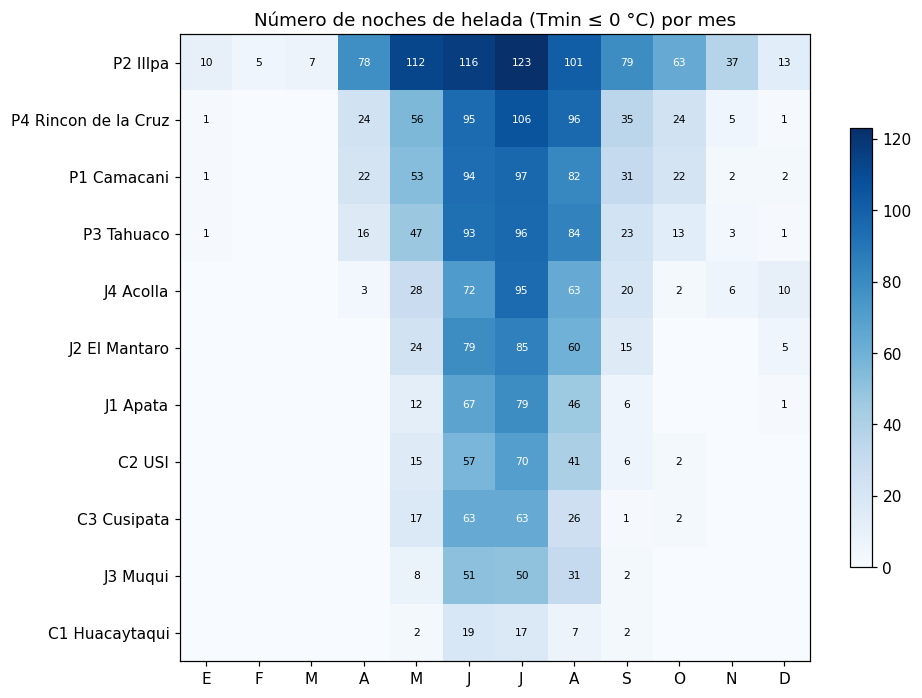

In [6]:
# Distribución mensual de las noches de helada (estaciones con heladas)
est_hel = resumen[resumen['heladas'] > 0].index
mes = (HEL.assign(mes=HEL.index.month, etq=HEL['estacion'].map(ETQ))
          .pivot_table(index='etq', columns='mes', values='tmin', aggfunc='size', fill_value=0)
          .reindex(columns=range(1, 13), fill_value=0).loc[est_hel])
fig, ax = plt.subplots(figsize=(9, 0.45 * len(mes) + 1.5))
im = ax.imshow(mes.values, cmap='Blues', aspect='auto')
ax.set_xticks(range(12), ['E', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
ax.set_yticks(range(len(mes)), mes.index); ax.grid(False)
for i in range(mes.shape[0]):
    for j in range(12):
        v = mes.values[i, j]
        if v: ax.text(j, i, v, ha='center', va='center', fontsize=7, color='w' if v > mes.values.max() / 2 else 'k')
ax.set_title('Número de noches de helada (Tmin ≤ 0 °C) por mes')
plt.colorbar(im, ax=ax, shrink=.7); plt.tight_layout(); plt.show()

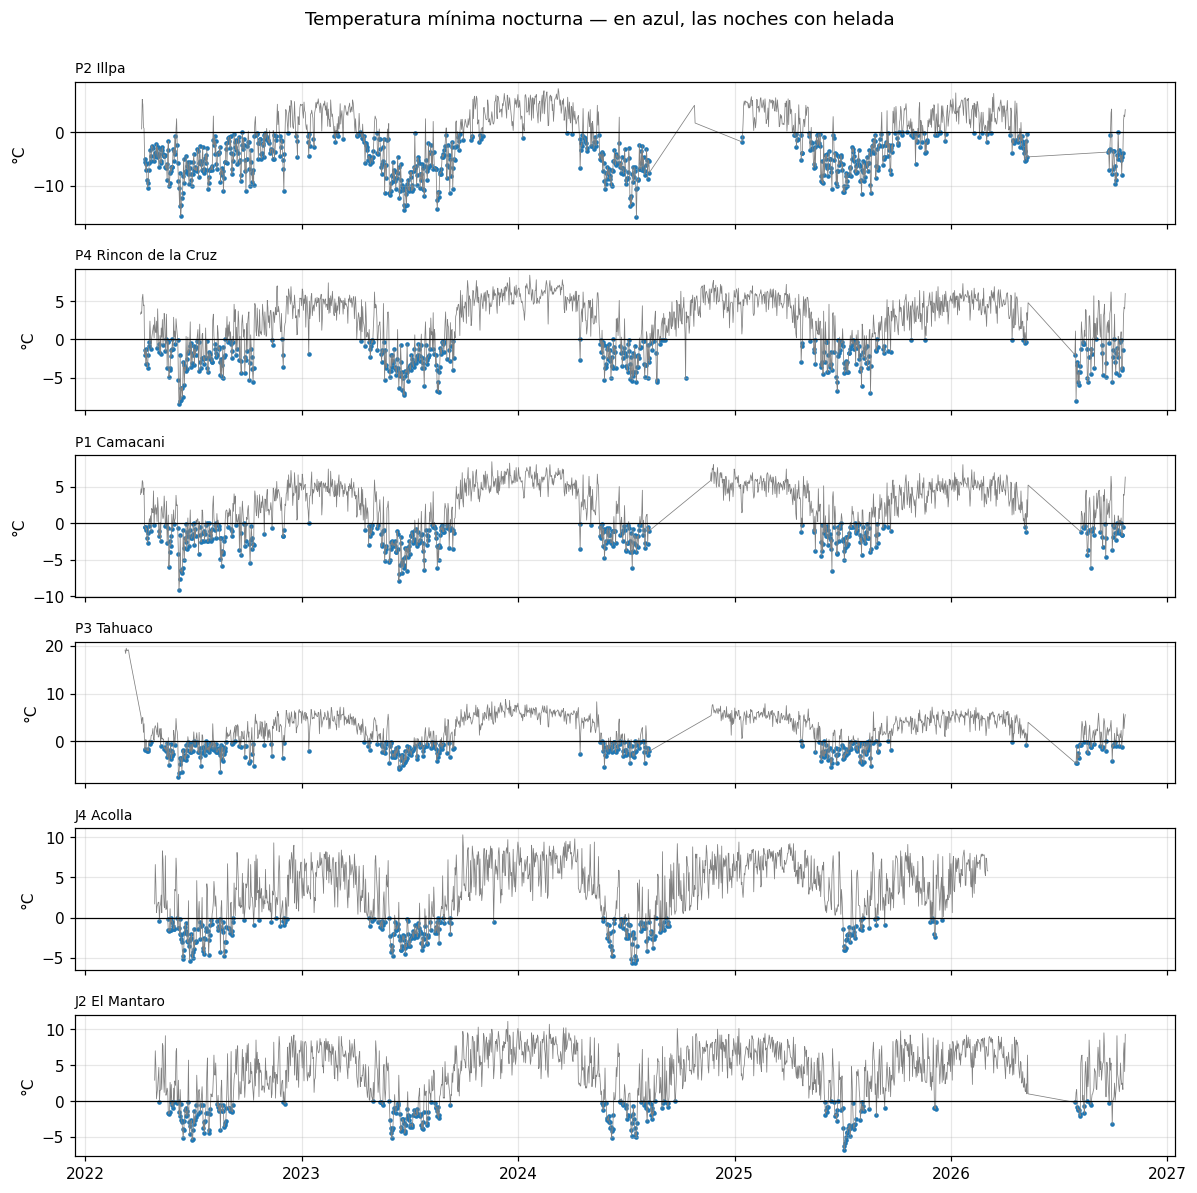

In [7]:
# Serie temporal de Tmin nocturna (estaciones con más heladas)
top = [e for e in NOCHES.groupby('estacion')['helada'].sum().sort_values(ascending=False).index][:6]
fig, axs = plt.subplots(len(top), 1, figsize=(11, 1.8 * len(top)), sharex=True)
for ax, e in zip(axs, top):
    s = NOCHES[NOCHES.estacion == e]['tmin']
    ax.plot(s.index, s, lw=.5, color='0.5')
    h = s[s <= T_HELADA]
    ax.scatter(h.index, h, s=4, color='tab:blue')
    ax.axhline(0, color='k', lw=.8); ax.set_ylabel('°C'); ax.set_title(ETQ[e], fontsize=9, loc='left')
plt.suptitle('Temperatura mínima nocturna — en azul, las noches con helada', y=1.0); plt.tight_layout(); plt.show()

## 3. Exploración de la humedad de hoja

Primero vemos **la escala y la forma de la distribución**. Un sensor de HR no debería tener valores cerca de 0 % ni por encima de 100 %, y su mediana debería parecerse a la HR del aire.

In [8]:
def describe_hoja(est):
    d = D[est]
    filas = {}
    for k in ['hoja_arriba', 'hoja_bajo']:
        s = d[k].dropna()
        if s.empty: continue
        filas[k] = {
            'n': len(s), 'min': s.min(), 'p05': s.quantile(.05), 'p50': s.median(),
            'p95': s.quantile(.95), 'max': s.max(),
            'pct_enteros': 100 * (s % 1 == 0).mean(), 'valores_distintos': s.nunique(),
            'pct_>100': 100 * (s > 100).mean(), 'pct_<=10': 100 * (s <= 10).mean(),
            'HR_aire_p50': d.loc[s.index, 'HR'].median(),
            'corr_con_HR': s.corr(d.loc[s.index, 'HR']),
        }
    return pd.DataFrame(filas).T

desc = pd.concat({ETQ[e]: describe_hoja(e) for e in con_hoja}).round(2)
desc

n  min  p05   p50    p95    max  pct_enteros  valores_distintos  pct_>100  pct_<=10  HR_aire_p50  corr_con_HR
C1 Huacaytaqui               hoja_arriba   9677.0  0.0  1.0   3.0   49.0  109.0        100.0              110.0      0.44     80.80         62.0         0.51
                             hoja_bajo     9665.0  0.0  0.0   1.0   24.0  109.0        100.0              108.0      0.56     91.52         62.0         0.40
C2 USI                       hoja_arriba  35150.0  0.0  1.0   3.0   65.0  110.0        100.0              111.0      0.71     72.31         75.0         0.53
                             hoja_bajo    31886.0  0.0  1.0   4.0   40.0  110.0        100.0              111.0      0.57     84.82         74.0         0.40
C3 Cusipata                  hoja_arriba  21566.0  0.0  2.0   3.0   44.0  108.0        100.0              106.0      0.06     77.11         66.0         0.52
                             hoja_bajo    21533.0  0.0  2.0   3.0   39.0  110.0        100.0              111.0      0.33     81.72         66.0         0.45
EEA Donoso                   hoja_arriba  21136.0  0.0  6.0  30.0  103.0  110.0        100.0              111.0      6.44     17.80         81.0         0.55
                             hoja_bajo    27396.0  0.0  4.0  35.0  110.0  110.0        100.0              111.0     13.67     21.81         84.0         0.53
EEA El Chira                 hoja_arriba  33561.0  1.0  3.0  10.0  107.0  110.0        100.0              110.0      5.83     51.23         76.0         0.58
                             hoja_bajo    33561.0  1.0  2.0   7.0   30.0  110.0        100.0               95.0      0.02     66.99         76.0         0.62
EEA Santa Rita               hoja_arriba  37802.0  0.0  0.0   2.0   47.0  109.0        100.0              110.0      2.68     89.50         46.0         0.55
                             hoja_bajo    37802.0  0.0  0.0   1.0   30.0  109.0        100.0              110.0      0.86     89.46         46.0         0.57
J1 Apata                     hoja_arriba  34796.0  1.0  3.0   5.0   70.0  110.0        100.0              110.0      1.99     64.63         71.0         0.58
                             hoja_bajo    34796.0  1.0  2.0   4.0   68.0  109.0        100.0              109.0      0.08     77.93         71.0         0.53
J2 El Mantaro                hoja_arriba  37439.0  1.0  4.0   6.0   84.0  109.0        100.0              109.0      3.19     62.15         71.0         0.61
                             hoja_bajo    37439.0  0.0  3.0   5.0   75.0  109.0        100.0              110.0      0.62     75.26         71.0         0.55
J3 Muqui                     hoja_arriba  36319.0  1.0  3.0   5.0   89.0  110.0        100.0              110.0      3.92     69.58         69.0         0.56
                             hoja_bajo    36319.0  1.0  2.0   4.0   57.1  110.0        100.0              109.0      0.07     84.11         69.0         0.48
J4 Acolla                    hoja_arriba  33758.0  1.0  2.0   6.0  103.0  109.0        100.0              109.0      5.53     56.27         71.0         0.52
                             hoja_bajo    33758.0  1.0  2.0   4.0   62.0  109.0        100.0              109.0      0.96     83.53         71.0         0.46
J5 San Jose de Villa Rica    hoja_arriba  37404.0  2.0  5.0  13.0  100.0  110.0        100.0              109.0      4.96     44.00         92.0         0.44
                             hoja_bajo    37368.0  0.0  3.0  10.0   71.0  110.0        100.0              111.0      0.46     52.94         92.0         0.44
L1 Lambayeque - Jayanca      hoja_arriba  27691.0  1.0  3.0  11.0   41.0  110.0        100.0              110.0      0.14     48.06         75.0         0.62
                             hoja_bajo    25585.0  0.0  2.0  16.0   97.0  110.0        100.0              111.0      3.93     41.73         74.0         0.63
L2 Lambayeque - Motupe       hoja_arriba  36071.0  1.0  2.0  10.0   88.0  110.0        100.0      

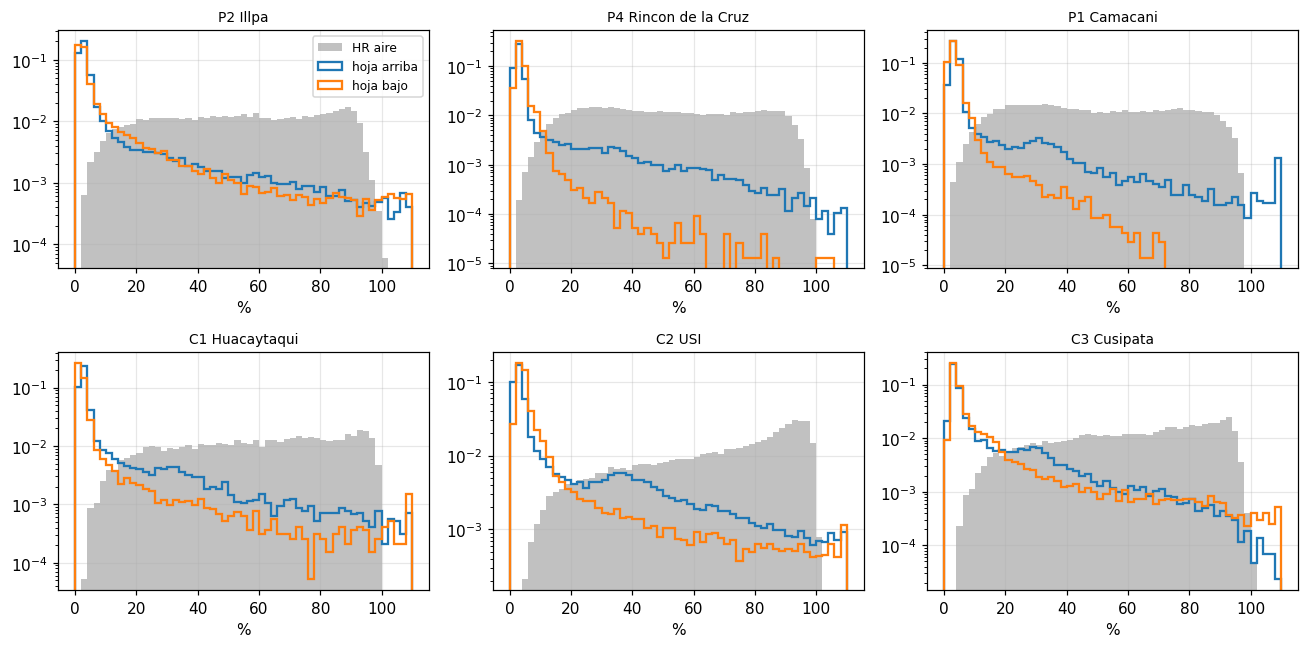

In [9]:
# Histogramas: hoja (arriba / bajo) frente a HR del aire, en algunas estaciones
ej = [e for e in top if e in con_hoja][:3] + [e for e in con_hoja if e not in top][:3]
fig, axs = plt.subplots(2, 3, figsize=(12, 6))
bins = np.arange(0, 112, 2)
for ax, e in zip(axs.flat, ej):
    d = D[e]
    ax.hist(d['HR'].dropna(), bins=bins, alpha=.4, label='HR aire', color='0.4', density=True)
    ax.hist(d['hoja_arriba'].dropna(), bins=bins, histtype='step', lw=1.5, label='hoja arriba', density=True)
    ax.hist(d['hoja_bajo'].dropna(), bins=bins, histtype='step', lw=1.5, label='hoja bajo', density=True)
    ax.set_yscale('log'); ax.set_title(ETQ[e], fontsize=9); ax.set_xlabel('%')
axs[0, 0].legend(fontsize=8); plt.tight_layout(); plt.show()

### 3.1 Prueba A — ¿la variable "hoja" es una HR?

Si fuera un sensor de HR, la nube hoja–HR del aire se acercaría a la recta 1:1. Un sensor de **mojado** da una relación en forma de "L": vale ≈ 0 en casi todo el rango de HR y solo sube cuando el aire se acerca a la saturación (HR > 90–95 %).

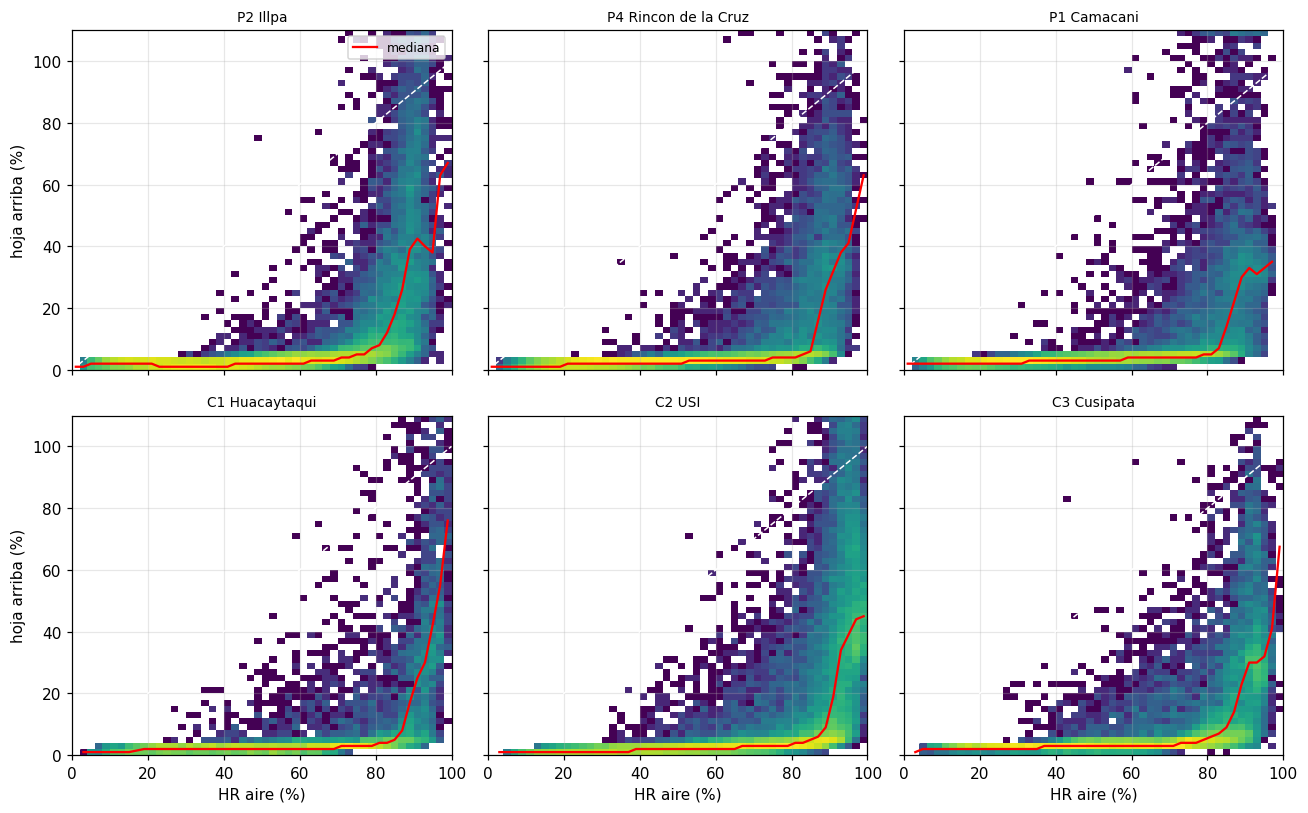

In [10]:
fig, axs = plt.subplots(2, 3, figsize=(12, 7.5), sharex=True, sharey=True)
for ax, e in zip(axs.flat, ej):
    d = D[e][['HR', 'hoja_arriba']].dropna()
    ax.hist2d(d['HR'], d['hoja_arriba'], bins=[np.arange(0, 102, 2), np.arange(0, 112, 2)],
              cmap='viridis', norm=plt.matplotlib.colors.LogNorm())
    ax.plot([0, 100], [0, 100], 'w--', lw=1)
    med = d.groupby(pd.cut(d['HR'], np.arange(0, 102, 2)), observed=True)['hoja_arriba'].median()
    ax.plot([i.mid for i in med.index], med.values, 'r-', lw=1.5, label='mediana')
    ax.set_title(ETQ[e], fontsize=9)
for ax in axs[-1]: ax.set_xlabel('HR aire (%)')
for ax in axs[:, 0]: ax.set_ylabel('hoja arriba (%)')
axs[0, 0].legend(fontsize=8); plt.tight_layout(); plt.show()

### 3.2 Respuesta a la depresión del punto de rocío y a la lluvia

El rocío se forma en la hoja cuando su superficie se enfría por debajo de Td. Con el aire a 2 m eso suele ocurrir cuando T−Td ≤ 1–2 °C. Un sensor de mojado muestra un **umbral**; un sensor de HR muestra una curva suave y monótona.

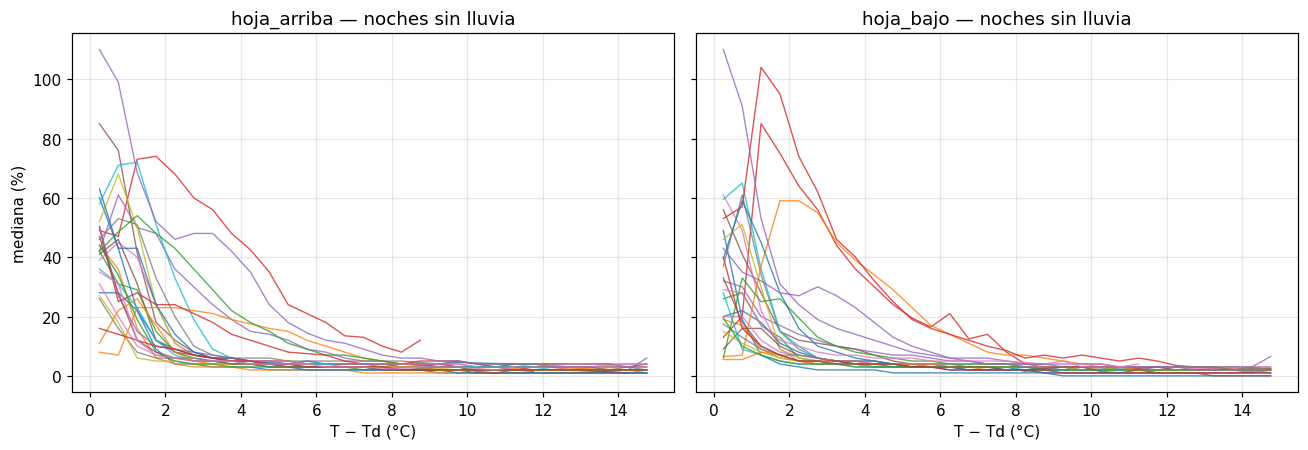

,arriba_lluvia,arriba_seco_dia,bajo_lluvia,bajo_seco_dia
C1 Huacaytaqui,30.0,2.0,3.0,1.0
C2 USI,43.0,2.0,11.0,3.0
C3 Cusipata,30.0,3.0,8.0,3.0
EEA Donoso,83.5,13.0,108.0,9.0
EEA El Chira,69.0,4.0,35.0,4.0
EEA Santa Rita,109.0,2.0,76.5,1.0
J1 Apata,32.0,4.0,8.0,3.0
J2 El Mantaro,31.0,5.0,8.0,4.0
J3 Muqui,40.0,4.0,7.0,3.0
J4 Acolla,35.0,3.0,7.0,3.0


In [11]:
bins_dep = np.arange(0, 15.5, 0.5)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, k in zip(axs, ['hoja_arriba', 'hoja_bajo']):
    for e in con_hoja:
        d = D[e]
        d = d[d['es_noche'] & (d['pp'].fillna(0) == 0)]
        m = d.groupby(pd.cut(d['dep'], bins_dep), observed=True)[k].median()
        ax.plot([i.mid for i in m.index], m.values, lw=.9, alpha=.8)
    ax.set_title(f'{k} — noches sin lluvia'); ax.set_xlabel('T − Td (°C)')
axs[0].set_ylabel('mediana (%)'); plt.tight_layout(); plt.show()

# Lluvia: valor de la hoja en horas con lluvia frente a horas secas
lluvia = pd.DataFrame({ETQ[e]: {
    'arriba_lluvia': D[e].loc[D[e]['pp'] > 0.2, 'hoja_arriba'].median(),
    'arriba_seco_dia': D[e].loc[(D[e]['pp'].fillna(0) == 0) & D[e].index.hour.isin(range(11, 16)), 'hoja_arriba'].median(),
    'bajo_lluvia': D[e].loc[D[e]['pp'] > 0.2, 'hoja_bajo'].median(),
    'bajo_seco_dia': D[e].loc[(D[e]['pp'].fillna(0) == 0) & D[e].index.hour.isin(range(11, 16)), 'hoja_bajo'].median(),
} for e in con_hoja}).T
lluvia

### 3.3 Ciclo diario, cara arriba frente a cara abajo

Si "arriba" y "bajo" fueran las dos caras de una hoja artificial, o dos alturas del dosel, la cara de arriba debería mojarse más de noche: pierde calor por radiación hacia el cielo y se forma más rocío o escarcha, y además recibe la lluvia directamente.

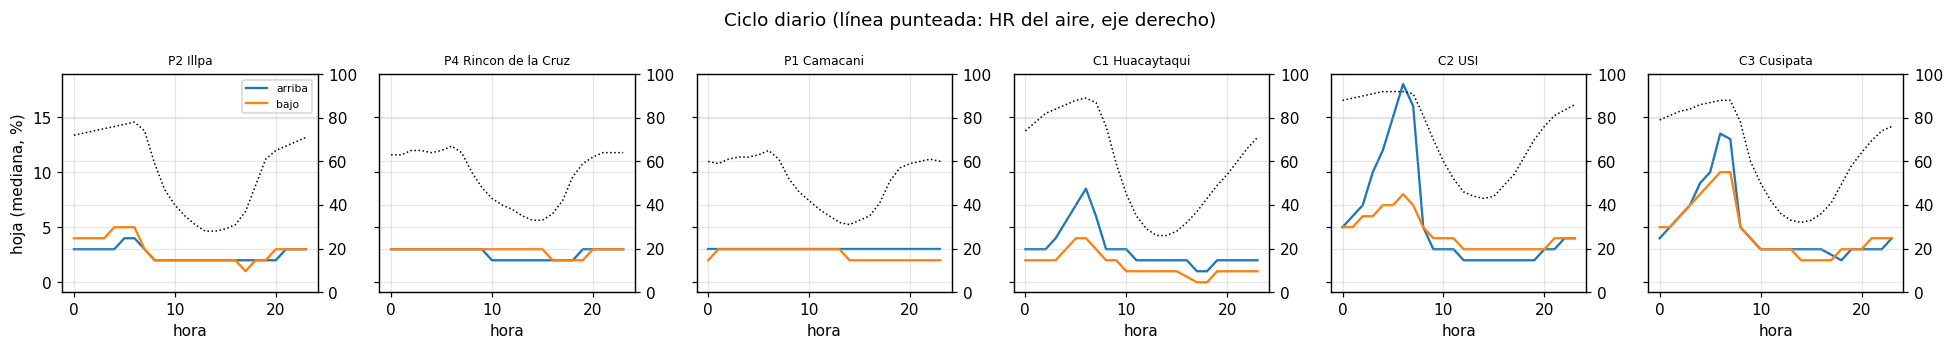

In [12]:
fig, axs = plt.subplots(1, len(ej), figsize=(3 * len(ej), 3.2), sharey=True)
for ax, e in zip(axs, ej):
    d = D[e]
    c = d.groupby(d.index.hour)[['hoja_arriba', 'hoja_bajo', 'HR']].median()
    ax.plot(c.index, c['hoja_arriba'], label='arriba'); ax.plot(c.index, c['hoja_bajo'], label='bajo')
    ax2 = ax.twinx(); ax2.plot(c.index, c['HR'], 'k:', lw=1); ax2.set_ylim(0, 100)
    ax.set_title(ETQ[e], fontsize=8); ax.set_xlabel('hora')
axs[0].set_ylabel('hoja (mediana, %)'); axs[0].legend(fontsize=7)
plt.suptitle('Ciclo diario (línea punteada: HR del aire, eje derecho)'); plt.tight_layout(); plt.show()

### 3.4 Dinámica de la señal: ¿saltos o cambios graduales?

Los sensores resistivos suelen dar una señal **"todo o nada"**: muchos cambios horarios cercanos a 0 y algunos saltos grandes. Los dieléctricos y los de HR cambian de forma más gradual.

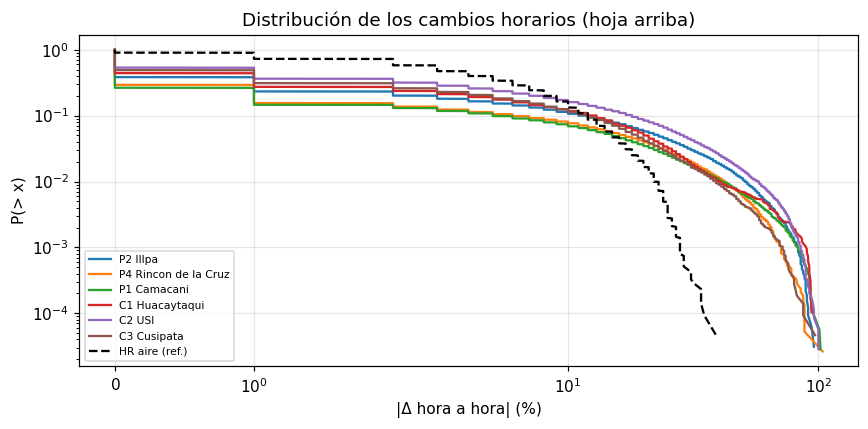

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
for e in ej:
    dif = D[e]['hoja_arriba'].diff().abs().dropna()
    dif = dif[D[e].loc[dif.index, 'hoja_arriba'].notna()]
    v = np.sort(dif.values); ax.plot(v, 1 - np.arange(len(v)) / len(v), label=ETQ[e])
    hr = np.sort(D[e]['HR'].diff().abs().dropna().values)
ax.plot(hr, 1 - np.arange(len(hr)) / len(hr), 'k--', label='HR aire (ref.)')
ax.set_xscale('symlog'); ax.set_yscale('log'); ax.set_xlabel('|Δ hora a hora| (%)'); ax.set_ylabel('P(> x)')
ax.legend(fontsize=7); ax.set_title('Distribución de los cambios horarios (hoja arriba)'); plt.tight_layout(); plt.show()

## 4. Prueba clave — comportamiento del sensor durante las heladas

Comparamos el valor del sensor en **cuatro condiciones** de cada estación:

| Condición | Definición | Agua en la hoja |
|---|---|---|
| **seco** | 11–15 h, sin lluvia, HR < 60 % | ninguna |
| **rocío** | noche, `Tmin` > 2 °C, T−Td ≤ 1 °C, sin lluvia | **líquida** |
| **hielo (escarcha)** | noche de helada blanca, `Tmax` de la hora < 0 °C, T−Td ≤ `DEP_ESCARCHA` | **sólida** |
| **helada negra** | noche de helada negra, `Tmax` < 0 °C | ninguna (aire seco) |

**Índice de hielo**: `IH = (hielo − seco) / (rocío − seco)`

* IH ≈ 0 → el sensor **no ve el hielo** → **resistivo** (hipótesis B).
* 0 < IH < 1 → el hielo da una señal intermedia → **dieléctrico** (hipótesis C).
* IH ≈ 1 y "seco" alto (> 20 %) → se comporta como **HR** (hipótesis A).

También medimos el **pico de deshielo**: el máximo del sensor en las 3 h siguientes a la primera hora con T > 0 °C tras el mínimo, menos su valor medio mientras estaba congelado.

In [14]:
est_sens = [e for e in con_hoja if NOCHES[(NOCHES.estacion == e)]['helada'].sum() >= MIN_NOCHES]
print('Estaciones con suficientes heladas para la prueba:', [ETQ[e] for e in est_sens])

def condiciones(est):
    d = D[est]
    hel = NOCHES[(NOCHES.estacion == est) & NOCHES.helada]
    blanca = d['noche'].isin(hel.index[hel.tipo == 'blanca'])
    negra = d['noche'].isin(hel.index[hel.tipo == 'negra'])
    sin_pp = d['pp'].fillna(0) == 0
    h = d.index.hour
    return {
        'seco': (h >= 11) & (h <= 15) & sin_pp & (d['HR'] < 60),
        'rocío': d['es_noche'] & sin_pp & (d['Tmin'] > 2) & (d['dep'] <= 1),
        'hielo': d['es_noche'] & sin_pp & blanca & (d['Tmax'] < 0) & (d['dep'] <= DEP_ESCARCHA),
        'helada negra': d['es_noche'] & sin_pp & negra & (d['Tmax'] < 0),
    }

filas = []
for e in est_sens:
    cond = condiciones(e)
    for k in ['hoja_arriba', 'hoja_bajo']:
        f = {'estacion': ETQ[e], 'sensor': k}
        for c, m in cond.items():
            s = D[e].loc[m, k].dropna()
            f[f'{c}'] = s.median(); f[f'n_{c}'] = len(s)
        filas.append(f)
COND = pd.DataFrame(filas)
COND['IH'] = (COND['hielo'] - COND['seco']) / (COND['rocío'] - COND['seco'])
COND.round(2)

Estaciones con suficientes heladas para la prueba: ['C1 Huacaytaqui', 'C2 USI', 'C3 Cusipata', 'J1 Apata', 'J2 El Mantaro', 'J3 Muqui', 'J4 Acolla', 'P1 Camacani', 'P2 Illpa', 'P3 Tahuaco', 'P4 Rincon de la Cruz']


,estacion,sensor,seco,n_seco,rocío,n_rocío,hielo,n_hielo,helada negra,n_helada negra,IH
0,C1 Huacaytaqui,hoja_arriba,2.0,1827,43.0,542,4.0,21,2.0,42,0.05
1,C1 Huacaytaqui,hoja_bajo,1.0,1827,22.0,542,3.0,21,1.0,42,0.10
2,C2 USI,hoja_arriba,2.0,5064,40.0,3987,16.0,24,1.0,90,0.37
3,C2 USI,hoja_bajo,3.0,4740,16.0,3290,26.0,27,2.0,90,1.77
4,C3 Cusipata,hoja_arriba,3.0,4024,31.0,721,9.0,32,2.0,157,0.21
5,C3 Cusipata,hoja_bajo,3.0,4024,30.0,703,5.0,32,2.0,157,0.07
6,J1 Apata,hoja_arriba,4.0,6093,42.0,3575,13.0,320,4.0,94,0.24
7,J1 Apata,hoja_bajo,3.0,6093,54.0,3575,10.0,320,3.0,94,0.14
8,J2 El Mantaro,hoja_arriba,5.0,6426,54.0,3297,18.0,471,5.0,32,0.27
9,J2 El Mantaro,hoja_bajo,4.0,6426,62.0,3297,15.0,471,3.5,32,0.19


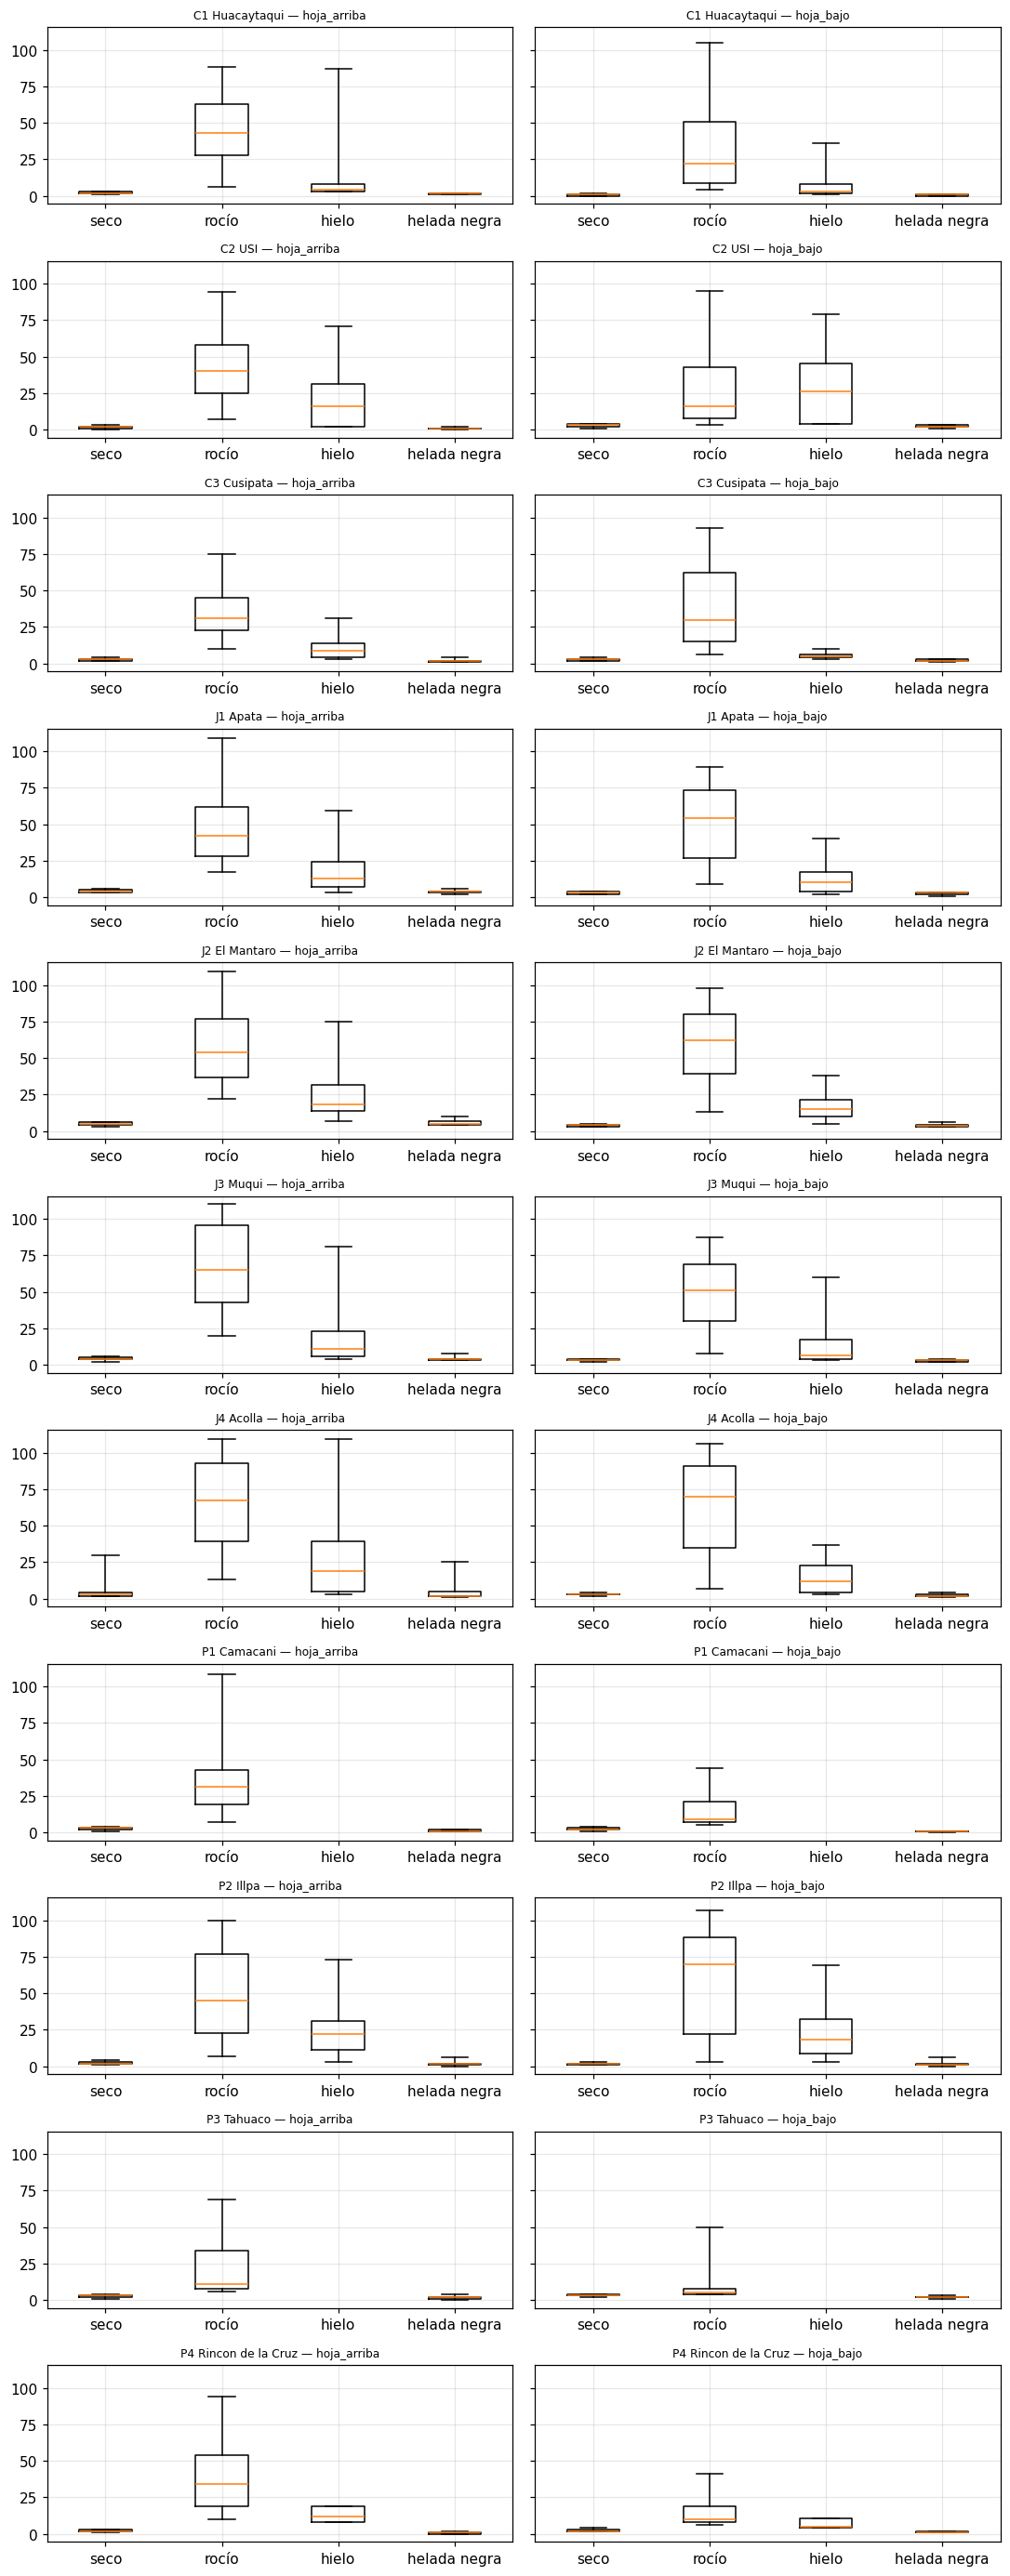

In [15]:
# Distribuciones por condición (boxplots), estaciones con heladas
fig, axs = plt.subplots(len(est_sens), 2, figsize=(10, 2.3 * len(est_sens)), sharey=True, squeeze=False)
for i, e in enumerate(est_sens):
    cond = condiciones(e)
    for j, k in enumerate(['hoja_arriba', 'hoja_bajo']):
        vals = [D[e].loc[m, k].dropna().values for m in cond.values()]
        axs[i, j].boxplot(vals, tick_labels=list(cond), showfliers=False, whis=(5, 95))
        axs[i, j].set_title(f'{ETQ[e]} — {k}', fontsize=8)
plt.tight_layout(); plt.show()

### 4.1 Composición de eventos alineados en el deshielo

Para cada noche de helada buscamos la **hora de deshielo** (h = 0): la primera hora después del mínimo con `T > 0 °C`. Promediamos todas las noches con ese alineamiento.

* **Resistivo**: hoja ≈ línea base mientras T < 0 y **pico marcado** en h = 0…+2 (el agua líquida conduce).
* **Dieléctrico**: hoja ya elevada mientras T < 0 (escarcha) y un aumento adicional moderado al fundirse.
* **HR**: sigue a la HR del aire, que **baja** al calentarse después del amanecer; no hay pico.

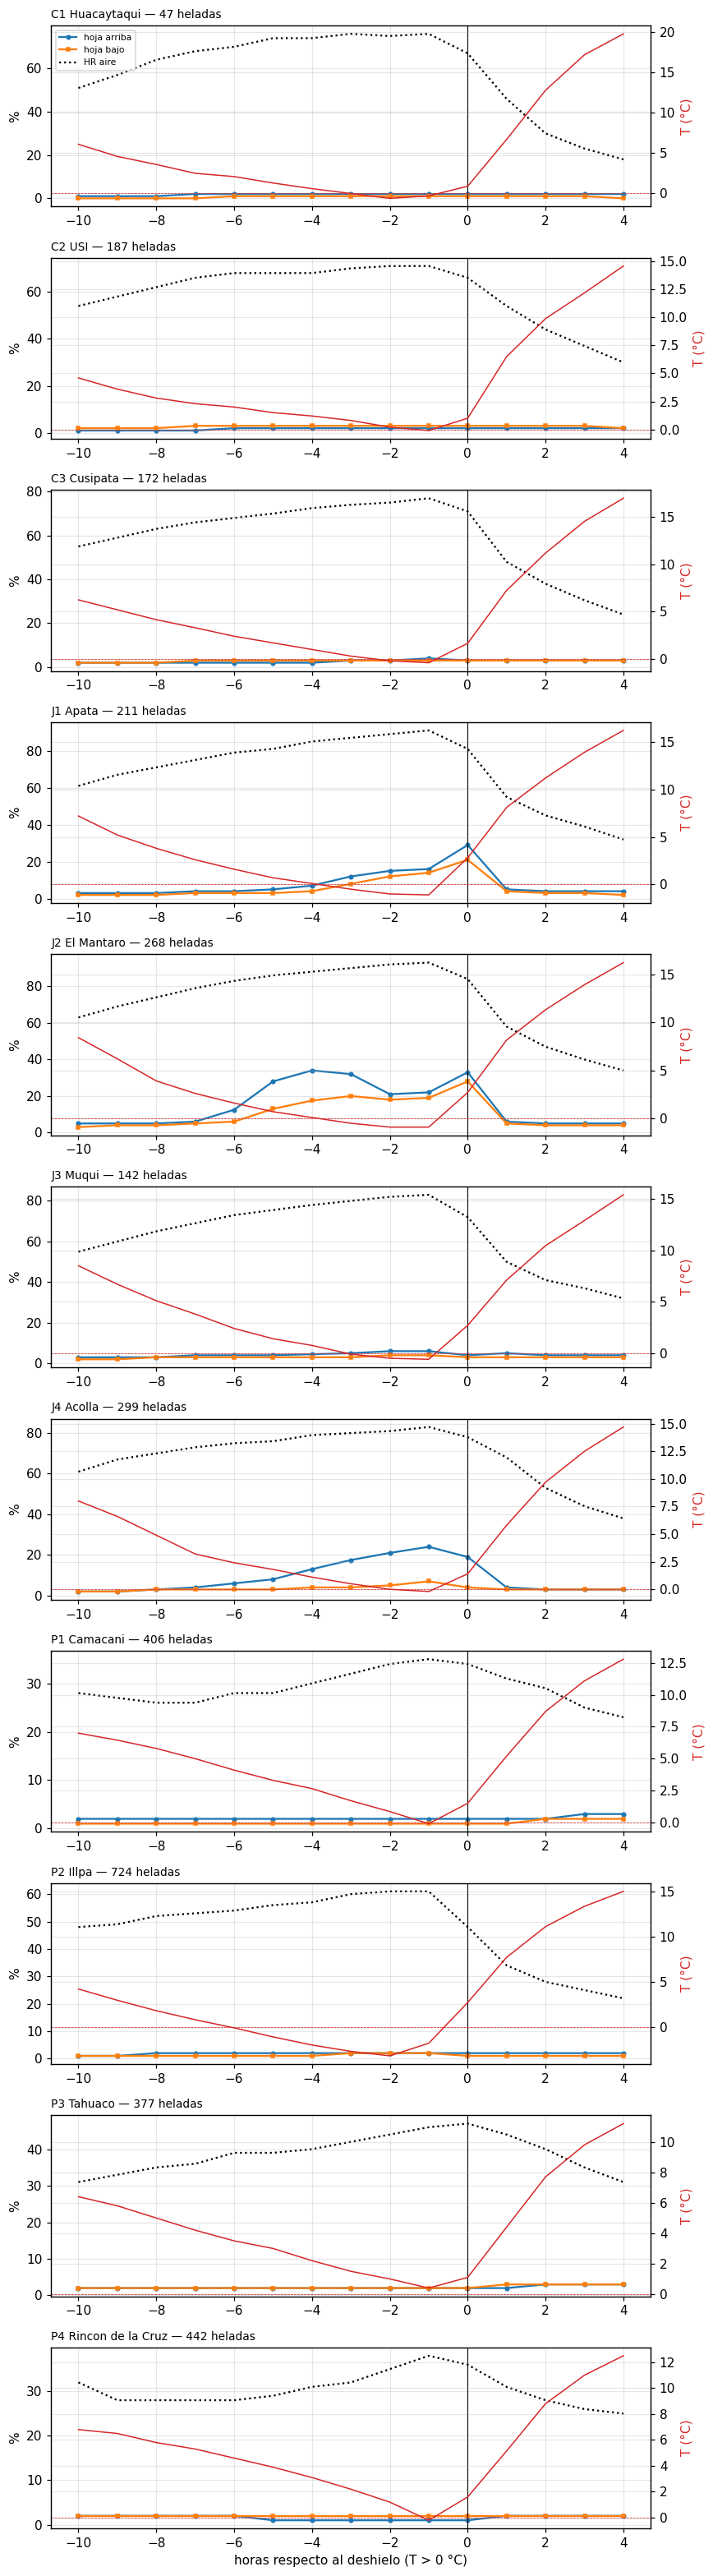

,estacion,sensor,n_eventos,congelado_med,max_post_deshielo_med,pico_deshielo,pct_eventos_con_pico>10
0,C1 Huacaytaqui,hoja_arriba,47,2.0,2.0,0.0,6.4
1,C1 Huacaytaqui,hoja_bajo,47,1.0,1.0,0.0,2.1
2,C2 USI,hoja_arriba,187,1.3,2.0,0.0,2.1
3,C2 USI,hoja_bajo,187,3.0,3.0,0.0,2.1
4,C3 Cusipata,hoja_arriba,172,2.3,3.0,0.2,0.6
5,C3 Cusipata,hoja_bajo,172,3.0,3.0,0.0,0.0
6,J1 Apata,hoja_arriba,211,14.6,30.0,3.4,26.5
7,J1 Apata,hoja_bajo,211,9.3,22.0,1.9,22.3
8,J2 El Mantaro,hoja_arriba,268,24.3,33.5,3.3,24.3
9,J2 El Mantaro,hoja_bajo,268,18.5,29.0,5.0,28.4


In [16]:
VENT = range(-10, 5)

def eventos_deshielo(est, tipo=None):
    d = D[est]
    hel = NOCHES[(NOCHES.estacion == est) & NOCHES.helada]
    if tipo: hel = hel[hel.tipo == tipo]
    evs = []
    for noche, r in hel.iterrows():
        if pd.isna(r['hora_tmin']): continue
        tramo = d.loc[r['hora_tmin']: noche + pd.Timedelta(hours=24 + H_FIN_EXT)]
        sobre0 = tramo.index[tramo['T'] > 0]
        if len(sobre0) == 0: continue
        t0 = sobre0[0]
        idx = [t0 + pd.Timedelta(hours=h) for h in VENT]
        ev = d.reindex(idx)[['T', 'HR', 'hoja_arriba', 'hoja_bajo', 'rad']]
        ev.index = list(VENT)
        if ev[['hoja_arriba', 'hoja_bajo']].notna().sum().min() < len(VENT) * .7: continue
        evs.append(ev.assign(noche=noche))
    return pd.concat(evs) if evs else None

PICO = []
fig, axs = plt.subplots(len(est_sens), 1, figsize=(8, 2.6 * len(est_sens)), squeeze=False)
for ax, e in zip(axs[:, 0], est_sens):
    ev = eventos_deshielo(e)
    if ev is None: continue
    comp = ev.groupby(level=0).median(numeric_only=True)
    ax.plot(comp.index, comp['hoja_arriba'], 'o-', ms=3, label='hoja arriba')
    ax.plot(comp.index, comp['hoja_bajo'], 's-', ms=3, label='hoja bajo')
    ax.plot(comp.index, comp['HR'], 'k:', label='HR aire')
    ax2 = ax.twinx(); ax2.plot(comp.index, comp['T'], color='tab:red', lw=1); ax2.axhline(0, color='tab:red', lw=.5, ls='--')
    ax2.set_ylabel('T (°C)', color='tab:red')
    ax.axvline(0, color='k', lw=.7); ax.set_title(f"{ETQ[e]} — {ev['noche'].nunique()} heladas", fontsize=9, loc='left')
    ax.set_ylabel('%')
    # pico de deshielo por evento
    for k in ['hoja_arriba', 'hoja_bajo']:
        piv = ev.pivot_table(index='noche', columns=ev.index, values=k)
        tcong = ev.pivot_table(index='noche', columns=ev.index, values='T')
        cong = piv.where(tcong < 0).mean(axis=1)
        post = piv[[0, 1, 2, 3]].max(axis=1)
        PICO.append({'estacion': ETQ[e], 'sensor': k, 'n_eventos': len(piv),
                     'congelado_med': cong.median(), 'max_post_deshielo_med': post.median(),
                     'pico_deshielo': (post - cong).median(),
                     'pct_eventos_con_pico>10': 100 * ((post - cong) > 10).mean()})
axs[0, 0].legend(fontsize=7, loc='upper left'); axs[-1, 0].set_xlabel('horas respecto al deshielo (T > 0 °C)')
plt.tight_layout(); plt.show()
PICO = pd.DataFrame(PICO); PICO.round(1)

In [17]:
# Blanca vs negra: si el sensor ve la escarcha, en heladas blancas debe estar más alto durante el congelamiento
filas = []
for e in est_sens:
    for tipo in ['blanca', 'negra']:
        ev = eventos_deshielo(e, tipo)
        if ev is None: continue
        cong = ev[ev['T'] < 0]
        filas.append({'estacion': ETQ[e], 'tipo': tipo, 'n': ev['noche'].nunique(),
                      'arriba_congelado': cong['hoja_arriba'].median(),
                      'bajo_congelado': cong['hoja_bajo'].median(),
                      'arriba_post': ev.loc[[0, 1, 2], 'hoja_arriba'].median(),
                      'bajo_post': ev.loc[[0, 1, 2], 'hoja_bajo'].median()})
pd.DataFrame(filas).round(1)

,estacion,tipo,n,arriba_congelado,bajo_congelado,arriba_post,bajo_post
0,C1 Huacaytaqui,blanca,19,4.0,3.0,4.0,2.0
1,C1 Huacaytaqui,negra,28,2.0,1.0,1.0,0.0
2,C2 USI,blanca,63,9.5,10.0,3.0,4.0
3,C2 USI,negra,124,1.0,2.0,1.0,2.0
4,C3 Cusipata,blanca,66,9.0,5.0,4.0,3.0
5,C3 Cusipata,negra,106,2.0,2.0,2.0,3.0
6,J1 Apata,blanca,178,11.0,7.0,5.0,4.0
7,J1 Apata,negra,33,4.0,3.0,4.0,3.0
8,J2 El Mantaro,blanca,245,18.0,15.0,6.0,5.0
9,J2 El Mantaro,negra,23,5.0,4.0,6.0,7.0


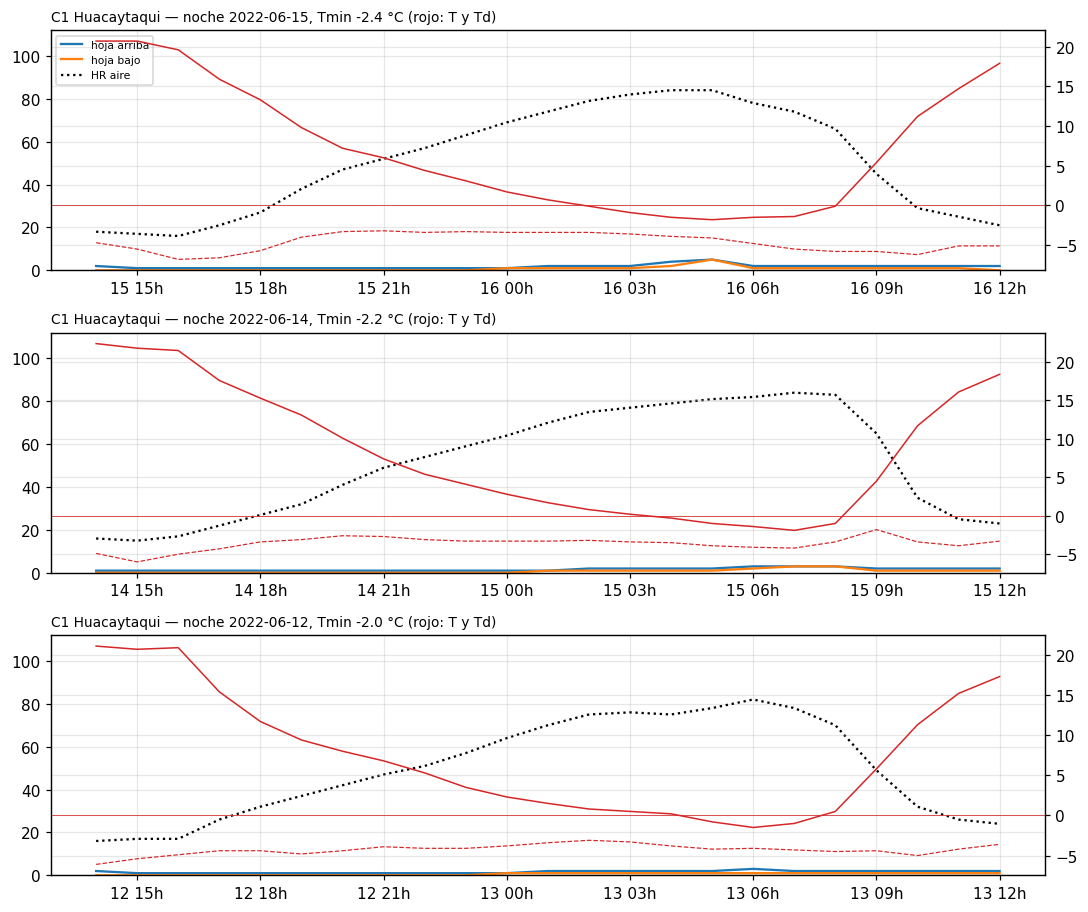

In [18]:
# Ejemplos de noches individuales: las 3 heladas blancas más intensas de la estación con más heladas
e = est_sens[0] if est_sens else None
if e:
    hel = NOCHES[(NOCHES.estacion == e) & (NOCHES.tipo == 'blanca')].nsmallest(3, 'tmin')
    fig, axs = plt.subplots(len(hel), 1, figsize=(10, 2.8 * len(hel)), squeeze=False)
    for ax, (noche, r) in zip(axs[:, 0], hel.iterrows()):
        t = D[e].loc[noche + pd.Timedelta(hours=14): noche + pd.Timedelta(hours=36)]
        ax.plot(t.index, t['hoja_arriba'], label='hoja arriba'); ax.plot(t.index, t['hoja_bajo'], label='hoja bajo')
        ax.plot(t.index, t['HR'], 'k:', label='HR aire'); ax.set_ylim(0, 112)
        ax2 = ax.twinx(); ax2.plot(t.index, t['T'], 'tab:red', lw=1); ax2.plot(t.index, t['Td'], 'tab:red', lw=.8, ls='--')
        ax2.axhline(0, color='tab:red', lw=.5)
        ax.set_title(f'{ETQ[e]} — noche {noche:%Y-%m-%d}, Tmin {r.tmin:.1f} °C (rojo: T y Td)', fontsize=9, loc='left')
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %Hh'))
    axs[0, 0].legend(fontsize=7, loc='upper left'); plt.tight_layout(); plt.show()

## 5. Diagnóstico por estación

Reglas de decisión (umbrales orientativos, ajustables):

1. **HR (A)**: mediana en "seco" > 20 % **y** correlación con la HR del aire > 0.85.
2. **Resistivo (B)**: no es HR, `IH` < 0.15 **y** pico de deshielo > 10 en la mayoría de los eventos.
3. **Dieléctrico (C)**: no es HR y `IH` ≥ 0.15 (el hielo da señal por encima de la de seco).
4. **Indeterminado** en los demás casos.

En las estaciones sin heladas no se puede aplicar la prueba del hielo; para ellas solo descartamos o confirmamos la hipótesis A.

In [19]:
corr = {(ETQ[e], k): D[e][k].corr(D[e]['HR']) for e in con_hoja for k in ['hoja_arriba', 'hoja_bajo']}
seco = {}
for e in con_hoja:
    d = D[e]; m = d.index.hour.isin(range(11, 16)) & (d['pp'].fillna(0) == 0) & (d['HR'] < 60)
    for k in ['hoja_arriba', 'hoja_bajo']:
        seco[(ETQ[e], k)] = d.loc[m, k].median()
DIAG = pd.DataFrame({'corr_HR': corr, 'seco_med': seco})
DIAG.index.names = ['estacion', 'sensor']
DIAG = DIAG.join(COND.set_index(['estacion', 'sensor'])[['rocío', 'hielo', 'IH']]) \
           .join(PICO.set_index(['estacion', 'sensor'])[['pico_deshielo', 'pct_eventos_con_pico>10']])

def veredicto(r):
    if r['seco_med'] > 20 and r['corr_HR'] > 0.85:
        return 'A · HR'
    if pd.isna(r['IH']):
        return 'no es HR (sin heladas para la prueba del hielo)'
    if r['IH'] < 0.15 and r.get('pct_eventos_con_pico>10', 0) >= 50:
        return 'B · resistivo'
    if r['IH'] >= 0.15:
        return 'C · dieléctrico'
    return 'indeterminado'

DIAG['veredicto'] = DIAG.apply(veredicto, axis=1)
DIAG.round(2).to_csv(OUT / 'diagnostico_sensor_hoja.csv')
DIAG.round(2)

corr_HR  seco_med  rocío  hielo    IH  pico_deshielo  pct_eventos_con_pico>10                                        veredicto
estacion                     sensor                                                                                                                                     
C1 Huacaytaqui               hoja_arriba     0.51       2.0   43.0    4.0  0.05           0.00                     6.38                                    indeterminado
                             hoja_bajo       0.40       1.0   22.0    3.0  0.10           0.00                     2.13                                    indeterminado
C2 USI                       hoja_arriba     0.53       2.0   40.0   16.0  0.37           0.00                     2.14                                  C · dieléctrico
                             hoja_bajo       0.40       3.0   16.0   26.0  1.77           0.00                     2.14                                  C · dieléctrico
C3 Cusipata                  hoja_arriba     0.52       3.0   31.0    9.0  0.21           0.25                     0.58                                  C · dieléctrico
                             hoja_bajo       0.45       3.0   30.0    5.0  0.07           0.00                     0.00                                    indeterminado
EEA Donoso                   hoja_arriba     0.55       7.0    NaN    NaN   NaN            NaN                      NaN  no es HR (sin heladas para la prueba del hielo)
                             hoja_bajo       0.53       4.5    NaN    NaN   NaN            NaN                      NaN  no es HR (sin heladas para la prueba del hielo)
EEA El Chira                 hoja_arriba     0.58       3.0    NaN    NaN   NaN            NaN                      NaN  no es HR (sin heladas para la prueba del hielo)
                             hoja_bajo       0.62       4.0    NaN    NaN   NaN            NaN                      NaN  no es HR (sin heladas para la prueba del hielo)
EEA Santa Rita               hoja_arriba     0.55       2.0    NaN    NaN   NaN            NaN                      NaN  no es HR (sin heladas para la prueba del hielo)
                             hoja_bajo       0.57       1.0    NaN    NaN   NaN            NaN                      NaN  no es HR (sin heladas para la prueba del hielo)
J1 Apata                     hoja_arriba     0.58       4.0   42.0   13.0  0.24           3.35                    26.54                                  C · dieléctrico
                             hoja_bajo       0.53       3.0   54.0   10.0  0.14           1.90                    22.27                                    indeterminado
J2 El Mantaro                hoja_arriba     0.61       5.0   54.0   18.0  0.27           3.33                    24.25                                  C · dieléctrico
                             hoja_bajo       0.55       4.0   62.0   15.0  0.19           5.00                    28.36                                  C · dieléctrico
J3 Muqui                     hoja_arriba     0.56       4.0   65.0   11.0  0.11           0.00                     4.93                                    indeterminado
                             hoja_bajo       0.48       3.0   51.0    6.5  0.07           0.00                     2.11                                    indeterminado
J4 Acolla                    hoja_arriba     0.52       3.0   67.0   19.0  0.25          -0.73                     4.68                                  C · dieléctrico
                             hoja_bajo       0.46       3.0   70.0   12.0  0.13           0.00                     6.02                                    indeterminado
J5 San Jose de Villa Rica    hoja_arriba     0.44       4.0    NaN    NaN   NaN            NaN                      NaN  no es HR (sin heladas para la prueba del hielo)
                             hoja_bajo       0.44       3.0    NaN    NaN   NaN            NaN                      NaN  no es HR (sin heladas para la prue

In [20]:
DIAG['veredicto'].value_counts()

veredicto
no es HR (sin heladas para la prueba del hielo)    36
C · dieléctrico                                    11
indeterminado                                       7
Name: count, dtype: int64

## 6. Interpretación y siguientes pasos

* Lee los resultados de las secciones 3.1 (forma de "L" o 1:1), 4 (índice `IH`) y 4.1 (pico de deshielo) **en conjunto**. Ninguna prueba es concluyente por sí sola.
* Un dato que conviene tener en cuenta: los valores son **enteros de 0 a ~110 %**. Una escala que pasa de 100 sugiere un **porcentaje de mojado calculado por el datalogger** a partir de una señal cruda (resistencia o frecuencia/permitividad), no una HR física, que no puede superar el 100 %.
* La mejor confirmación es documental: el modelo del sensor en la ficha de instalación o en el *datalogger* (nombre del canal, unidades crudas, fabricante de la estación).
* Si se confirma un sensor **resistivo**, el mojado durante las heladas (escarcha) estará **subestimado**. Para modelos de enfermedades conviene completarlo con criterios de HR ≥ 90 % y T−Td.